In [2]:
print('hello')

hello


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
file = r"C:\Users\ben\Downloads\exam_1_grades.csv"
df = pd.read_csv(file)
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\ben\\Downloads\\exam_1_grades.csv'

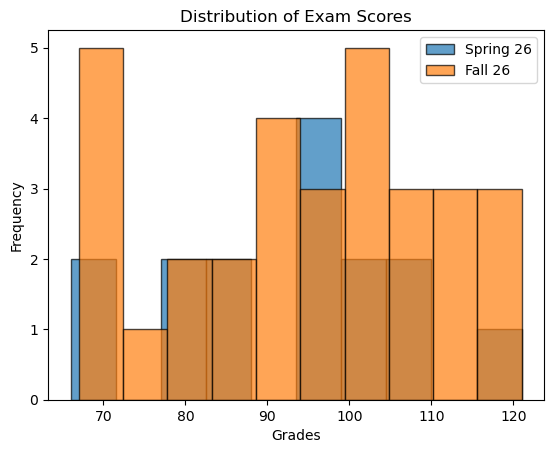

In [ ]:
plt.hist(df['Spring 26'], bins=10, edgecolor='black', alpha=0.7, label='Spring 26')
plt.hist(df['Fall 26'], bins=10, edgecolor='black', alpha=0.7, label='Fall 26')
plt.xlabel('Grades')
plt.ylabel('Frequency')
plt.title('Distribution of Exam Scores')
plt.legend()
plt.show()

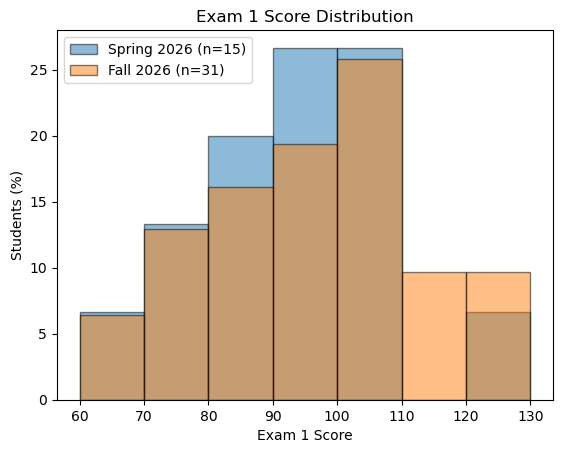

In [ ]:
bins = np.arange(60, 131, 10)

plt.hist(
    df['Spring 26'].dropna(),
    bins=bins,
    weights=np.ones(df['Spring 26'].dropna().shape[0]) / len(df['Spring 26'].dropna()) * 100,
    alpha=0.5,
    edgecolor='black',
    label='Spring 2026 (n=15)'
)

plt.hist(
    df['Fall 26'].dropna(),
    bins=bins,
    weights=np.ones(df['Fall 26'].dropna().shape[0]) / len(df['Fall 26'].dropna()) * 100,
    alpha=0.5,
    edgecolor='black',
    label='Fall 2026 (n=31)'
)

plt.xlabel('Exam 1 Score')
plt.ylabel('Students (%)')
plt.title('Exam 1 Score Distribution')
plt.legend()
plt.show()

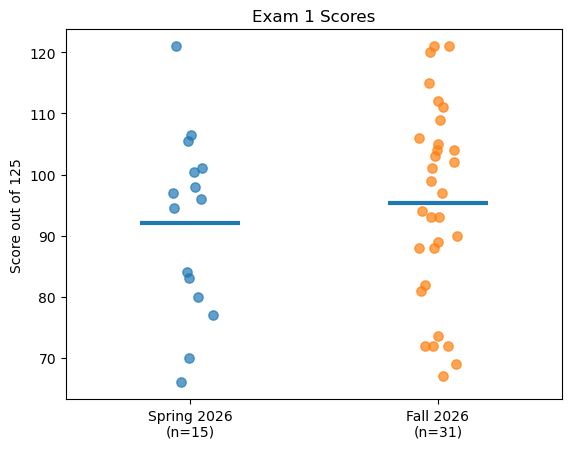

In [ ]:
spring = df['Spring 26'].dropna()
fall = df['Fall 26'].dropna()

x1 = np.random.normal(1, 0.04, len(spring))
x2 = np.random.normal(2, 0.04, len(fall))

plt.Figure(figsize=(8, 6))
plt.scatter(x1, spring, alpha=0.7, s=45)
plt.scatter(x2, fall, alpha=0.7, s=45)

plt.hlines(spring.mean(), 0.8, 1.2, linewidth=3)
plt.hlines(fall.mean(), 1.8, 2.2, linewidth=3)

plt.xticks([1, 2], ['Spring 2026\n(n=15)', 'Fall 2026\n(n=31)'])
plt.ylabel('Score out of 125')
plt.title('Exam 1 Scores')
plt.xlim(0.5, 2.5)

plt.show()

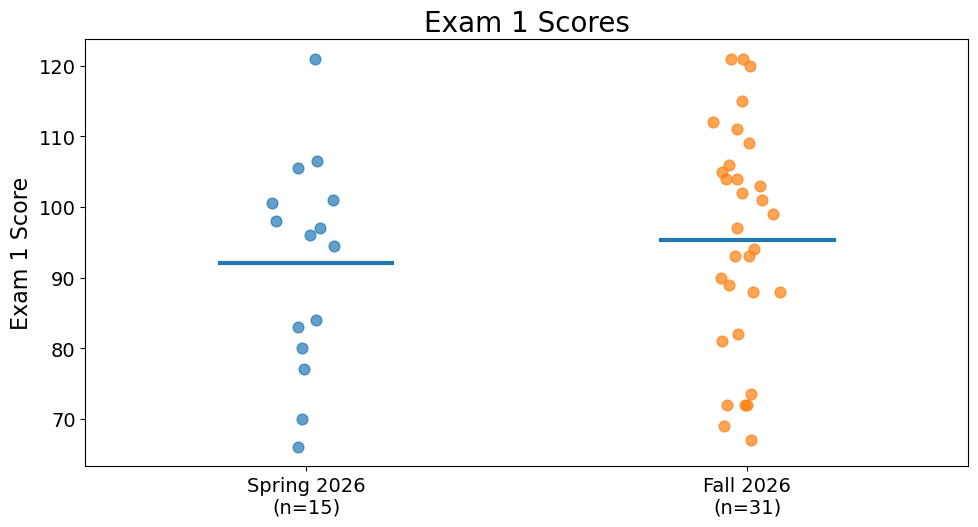

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

np.random.seed(42)

spring = df['Spring 26'].dropna()
fall = df['Fall 26'].dropna()

x1 = np.random.normal(1, 0.04, len(spring))
x2 = np.random.normal(2, 0.04, len(fall))

ax.scatter(x1, spring, alpha=0.7, s=60)
ax.scatter(x2, fall, alpha=0.7, s=60)

ax.hlines(spring.mean(), 0.8, 1.2, linewidth=3)
ax.hlines(fall.mean(), 1.8, 2.2, linewidth=3)

ax.set_xticks([1, 2])
ax.set_xticklabels(['Spring 2026\n(n=15)', 'Fall 2026\n(n=31)'])
ax.set_ylabel('Exam 1 Score')
ax.set_title('Exam 1 Scores')

ax.set_xlim(0.5, 2.5)


plt.tight_layout()
plt.show()

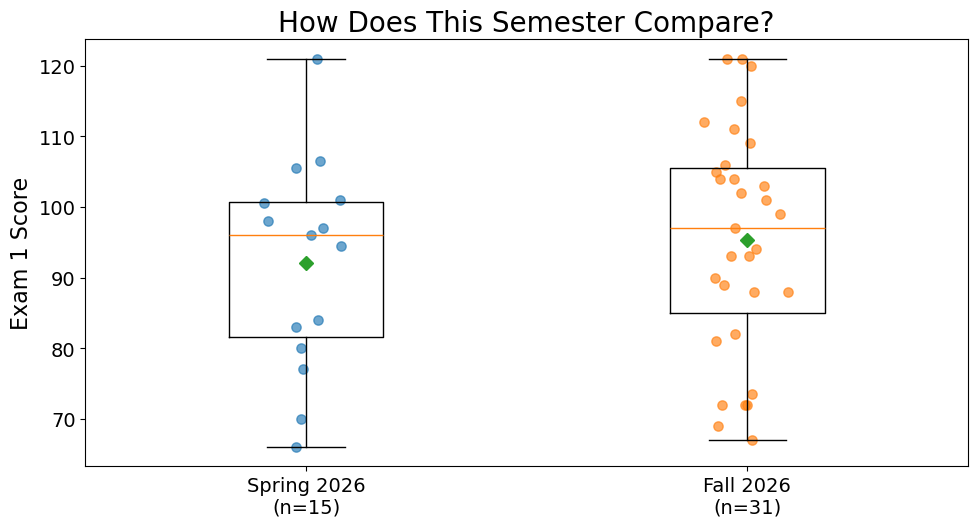

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

data = [spring, fall]

ax.boxplot(
    data,
    widths=0.35,
    showmeans=True,
    meanprops=dict(marker='D', markersize=7)
)

np.random.seed(42)
for i, values in enumerate(data, start=1):
    x = np.random.normal(i, 0.05, len(values))
    ax.scatter(x, values, alpha=0.65, s=45)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    'Spring 2026\n(n=15)',
    'Fall 2026\n(n=31)'
])

ax.set_ylabel('Exam 1 Score')
ax.set_title('How Does This Semester Compare?')

plt.tight_layout()
plt.show()

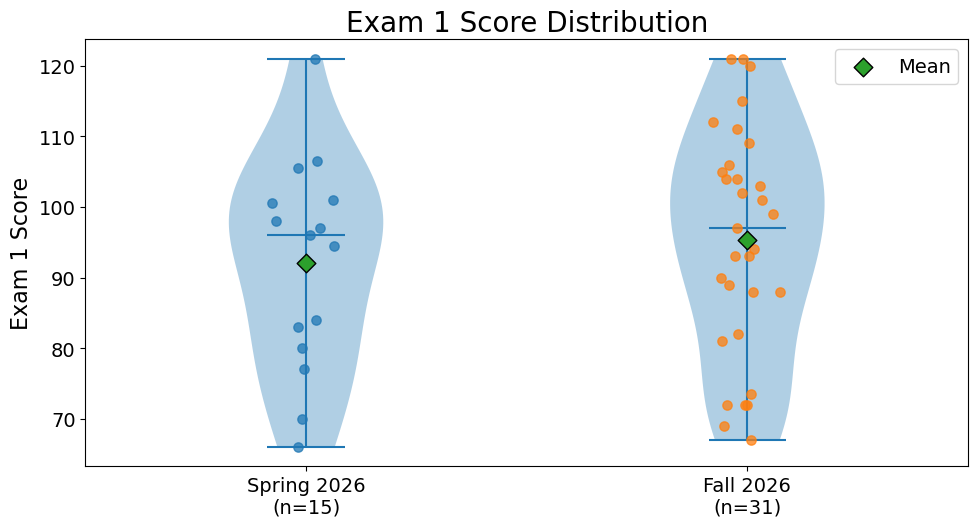

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Violin plots
parts = ax.violinplot(
    [spring, fall],
    positions=[1, 2],
    widths=0.35,
    showmeans=False,
    showmedians=True,
    showextrema=True
)

# Make violins slightly transparent
for body in parts['bodies']:
    body.set_alpha(0.35)

# Add individual students with a little jitter
np.random.seed(42)

x_spring = np.random.normal(1, 0.04, len(spring))
x_fall = np.random.normal(2, 0.04, len(fall))

ax.scatter(x_spring, spring, s=45, alpha=0.75, zorder=3)
ax.scatter(x_fall, fall, s=45, alpha=0.75, zorder=3)

# Labels
ax.set_xticks([1, 2])
ax.set_xticklabels([
    f'Spring 2026\n(n={len(spring)})',
    f'Fall 2026\n(n={len(fall)})'
])

ax.set_ylabel('Exam 1 Score')
ax.set_title('Exam 1 Score Distribution')

ax.set_xlim(0.5, 2.5)

ax.scatter(
    [1, 2],
    [spring.mean(), fall.mean()],
    marker='D',
    s=90,
    edgecolor='black',
    zorder=5,
    label='Mean'
)

ax.legend()

plt.tight_layout()
plt.show()

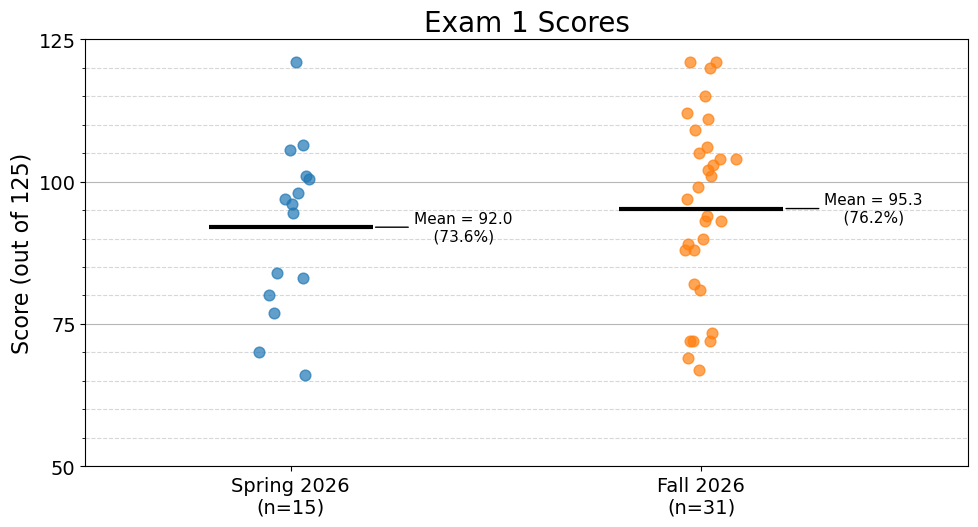

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# SETTINGS — change these by semester
# ---------------------------------------------------------

semester1_col = 'Spring 26'
semester2_col = 'Fall 26'

semester1_label = 'Spring 2026'
semester2_label = 'Fall 2026'

plot_title = 'Exam 1 Scores'
y_label = 'Score (out of 125)'

# ---------------------------------------------------------
# DATA
# ---------------------------------------------------------

semester1 = df[semester1_col].dropna()
semester2 = df[semester2_col].dropna()

data = [semester1, semester2]
labels = [semester1_label, semester2_label]
positions = [1, 2]

# ---------------------------------------------------------
# FIGURE
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

# Reproducible jitter
rng = np.random.default_rng(42)

for x, values in zip(positions, data):

    jitter = rng.normal(x, 0.04, len(values))

    # Individual students
    ax.scatter(
        jitter,
        values,
        alpha=0.7,
        s=60,
        zorder=2
    )

    # Mean
    mean = values.mean()

    ax.hlines(
        mean,
        x - 0.20,
        x + 0.20,
        color='black',
        linewidth=3,
        zorder=3
    )

    # Mean callout
    ax.annotate(
        f'Mean = {mean:.1f} \n    ({mean/125*100:.1f}%)',
        xy=(x + 0.20, mean),
        xytext=(x + 0.30, mean),
        va='center',
        fontsize=11,
        arrowprops=dict(
            arrowstyle='-',
            linewidth=1
        )
    )

# ---------------------------------------------------------
# LABELS
# ---------------------------------------------------------

ax.set_xticks(positions)

ax.set_xticklabels([
    f'{label}\n(n={len(values)})'
    for label, values in zip(labels, data)
])

ax.set_ylabel(y_label)
ax.set_title(plot_title)

ax.set_xlim(0.5, 2.65)

score_range = np.arange(50, 126, 25)

ax.set_ylim(50, 125)
ax.set_yticks(score_range)
ax.yaxis.set_minor_locator(plt.MultipleLocator(5))

ax.grid(which='major', axis='y', linestyle='-', alpha=0.9, zorder=10)
ax.grid(which='minor', axis='y', linestyle='--', alpha=0.5, zorder=10)

plt.tight_layout()
plt.show()

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
file = r"C:\Users\ben\Downloads\midterms.csv"
df = pd.read_csv(file)

df.head()

,Student ID,Midterm 1,Midterm 2
0,D34133174,97.0,107.0
1,K83923645,106.0,119.0
2,P07530419,88.0,93.5
3,S56447164,121.0,116.0
4,J21146044,81.0,106.0


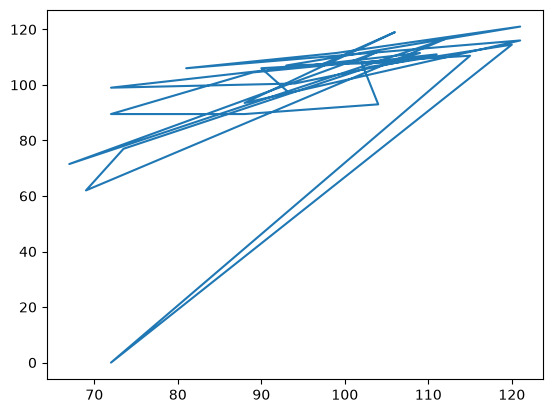

In [3]:
plt.plot(df['Midterm 1'], df['Midterm 2'])

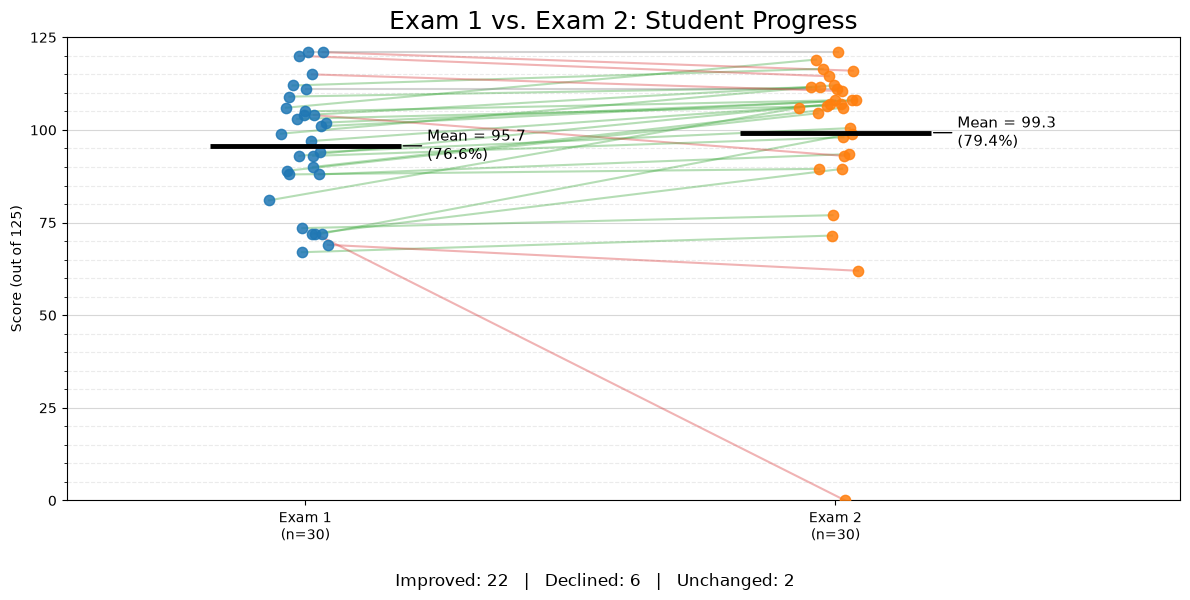

In [4]:


# ---------------------------------------------------------
# SETTINGS — change these for future exams
# ---------------------------------------------------------

exam1_col = 'Midterm 1'
exam2_col = 'Midterm 2'
student_id_col = 'Student ID'

exam1_label = 'Exam 1'
exam2_label = 'Exam 2'

plot_title = 'Exam 1 vs. Exam 2: Student Progress'
max_score = 125

# Options
color_by_change = True
show_mean = True
show_summary = True

# ---------------------------------------------------------
# DATA
# ---------------------------------------------------------

# Keep only students with scores on both exams
paired = df[
    [student_id_col, exam1_col, exam2_col]
].dropna().copy()

# Ensure each student appears only once
if paired[student_id_col].duplicated().any():
    raise ValueError('Duplicate student IDs found.')

exam1 = paired[exam1_col].to_numpy()
exam2 = paired[exam2_col].to_numpy()

change = exam2 - exam1

n_improved = np.sum(change > 0)
n_declined = np.sum(change < 0)
n_unchanged = np.sum(change == 0)

# ---------------------------------------------------------
# FIGURE
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

# Reproducible jitter
rng = np.random.default_rng(42)

# Same horizontal offset for each student's two scores
# so lines remain parallel to the overall progression
offsets = rng.normal(0, 0.035, len(paired))

x1 = 1 + offsets
x2 = 2 + offsets

# Draw connecting lines first
for i in range(len(paired)):

    if color_by_change:
        if change[i] > 0:
            color = 'tab:green'
        elif change[i] < 0:
            color = 'tab:red'
        else:
            color = 'gray'
    else:
        color = 'gray'

    ax.plot(
        [x1[i], x2[i]],
        [exam1[i], exam2[i]],
        color=color,
        alpha=0.35,
        linewidth=1.5,
        zorder=2
    )

# Individual exam scores
ax.scatter(
    x1, exam1,
    color='tab:blue',
    alpha=0.85,
    s=55,
    zorder=3
)

ax.scatter(
    x2, exam2,
    color='tab:orange',
    alpha=0.85,
    s=55,
    zorder=3
)

# ---------------------------------------------------------
# MEANS AND CALLOUTS
# ---------------------------------------------------------

if show_mean:

    for x, values in zip(
        [1, 2], [exam1, exam2]
    ):

        mean = values.mean()

        ax.hlines(
            mean,
            x - 0.18,
            x + 0.18,
            color='black',
            linewidth=3.5,
            zorder=5
        )

        ax.annotate(
            f'Mean = {mean:.1f}\n'
            f'({mean / max_score * 100:.1f}%)',
            xy=(x + 0.18, mean),
            xytext=(x + 0.23, mean),
            va='center',
            fontsize=11,
            arrowprops=dict(
                arrowstyle='-',
                linewidth=1,
                color='black'
            )
        )

# ---------------------------------------------------------
# LABELS
# ---------------------------------------------------------

ax.set_xticks([1, 2])

ax.set_xticklabels([
    f'{exam1_label}\n(n={len(paired)})',
    f'{exam2_label}\n(n={len(paired)})'
])

ax.set_ylabel(f'Score (out of {max_score})')
ax.set_title(plot_title, fontsize=18)

ax.set_xlim(0.55, 2.65)

# Score axis
ax.set_ylim(0, max_score)

ax.set_yticks(np.arange(0, max_score + 1, 25))
ax.yaxis.set_minor_locator(
    plt.MultipleLocator(5)
)

ax.set_axisbelow(True)

ax.grid(
    which='major',
    axis='y',
    linestyle='-',
    alpha=0.5
)

ax.grid(
    which='minor',
    axis='y',
    linestyle='--',
    alpha=0.25
)

# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------

if show_summary:

    summary = (
        f'Improved: {n_improved}   |   '
        f'Declined: {n_declined}   |   '
        f'Unchanged: {n_unchanged}'
    )

    fig.text(
        0.5, 0.015,
        summary,
        ha='center',
        fontsize=12
    )

plt.tight_layout(rect=[0, 0.06, 1, 1])

# Optional export for PowerPoint
# fig.savefig('exam_progress.png', dpi=300,
#             bbox_inches='tight')

plt.show()